# <b>Постановка задачи.</b>

Решается задача построения фильтра токсичных сделок. Для каждой сделки известны рыночные признаки $X_i$, вес сделки $w_i$ и реализованный maker PnL на выбранном горизонте $t$, например $30s$:

Задача модели - по признакам сделки предсказать ожидаемый PnL: $\hat y_i = f(X_i).$


## <b>Первый этап.</b>

Модель обучается на train-части и пытается предсказывать будущий PnL сделки.


## <b>Второй этап.</b>

Прогноз переводится в оценку токсичности сделки. Если модель предсказывает низкий PnL, то такая сделка считается более токсичной: $toxicit(y_i) = -\hat y_i.$

То есть чем меньше предсказанный PnL, тем выше токсичность сделки.

На calibration-части подбирается threshold. Для каждого возможного значения threshold строится бинарный фильтр:

$
a_i =
\begin{cases}
1, & toxicity_i > threshold, \\
0, & toxicity_i \le threshold.
\end{cases}
$

Threshold подбирается **только на calibration-части**. Цель подбора - максимизировать Score при ограничении на минимальный оставшийся оборот: $Score = PnL_{kept} - PnL_{all}.$


## <b>Схематично.</b>

```text
Features X
   ↓
Regression model on train
   ↓
Predicted PnL
   ↓
Toxicity = - Predicted PnL
   ↓
Threshold tuning on calib
   ↓
Embargo
   ↓
Final OOS test evaluation

## <b>Imports.</b>

In [1]:
import warnings


import numpy as np
import polars as pl
import pandas as pd


import utilities_task_4 as ut4
import utilities_models as um
import utilities_features as uf
import utilities_result as ur


from utilities_multiple_testing import (
    pairwise_dm_matrix,
    hansen_spa_test,
    model_confidence_set,
    romano_wolf_stepdown
)

from scipy.stats import norm


import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMRegressor was fitted with feature names", category=UserWarning)

## <b>Download data / Add more features.</b>

In [2]:
data = pl.read_parquet(f'data/enriched/eth_sub40.parquet')
data = uf.add_derived_features(data)

## <b>Global Variables.</b>

In [3]:
INSTRUMENT = "ETH"
HORIZONS = [30, 120, 300]
MAX_FILTER_RATES = [0.10, 0.20, 0.30, 0.50, 0.80, 0.90, 0.95]

## <b>One of the best baselines from Task 3.</b> 

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

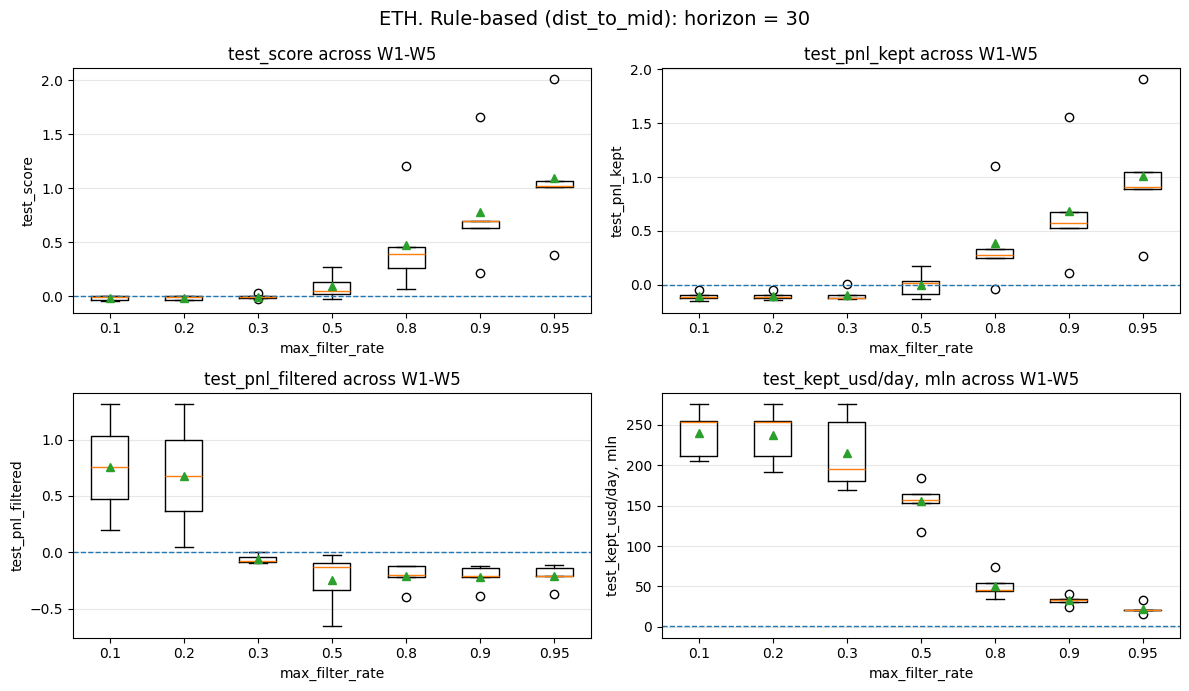

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

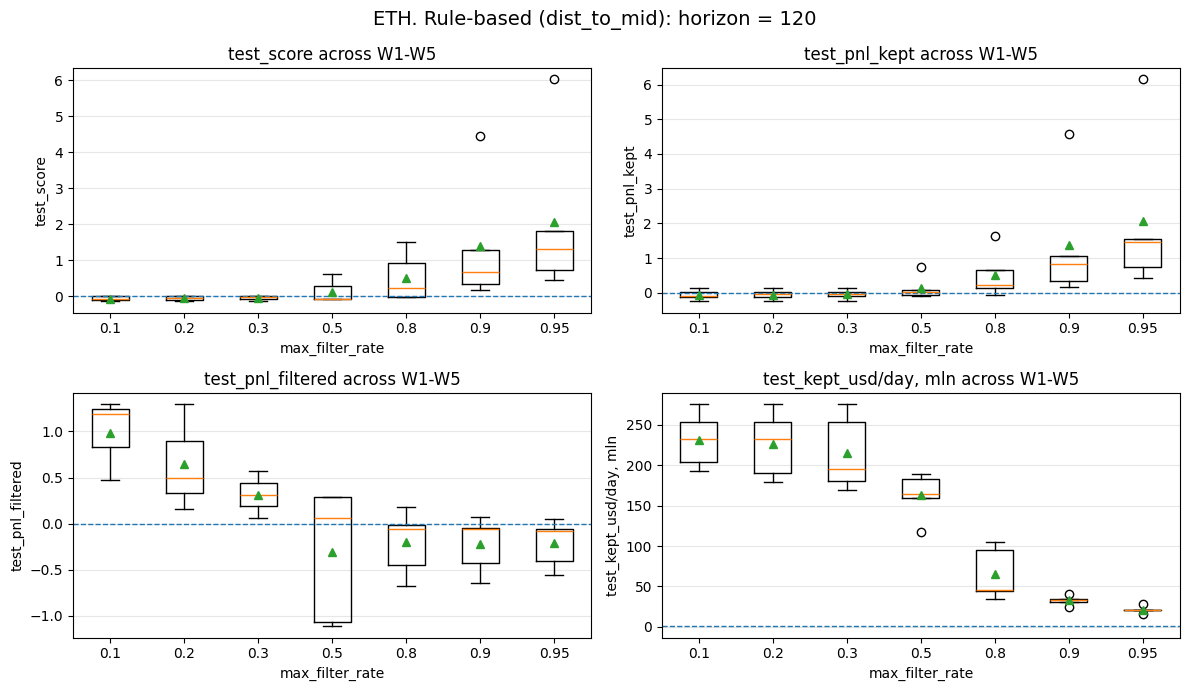

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

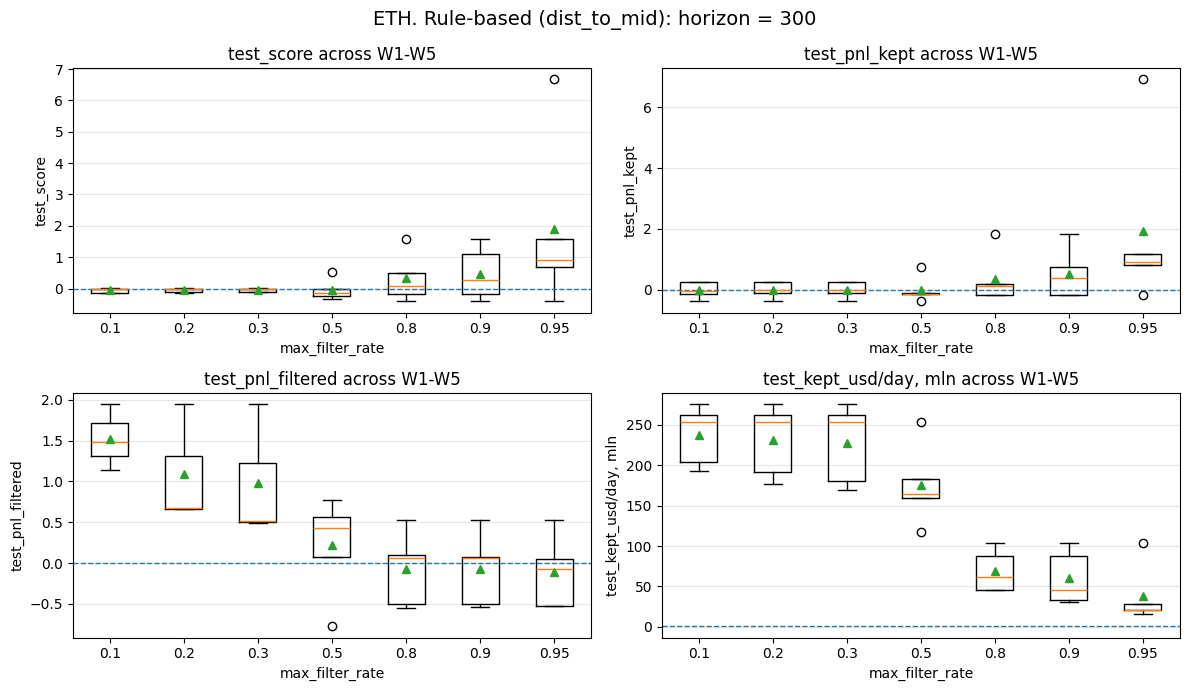

In [ ]:
config_rule = um.CUSTOM_MODELS["RuleBased_DistToMid"]
for tau in HORIZONS:

    rule_all, rule_models = ut4.run_walk_forward(
        df               = data,
        tau              = tau,
        train_fn         = config_rule["train_fn"],
        predict_fn       = config_rule["predict_fn"],
        prediction_type  = "toxicity",
        max_filter_rates = MAX_FILTER_RATES,
        calib_frac       = 0.20
    )

    ur.plot_test_metrics_boxplots(
        result_table = rule_all,
        model_name   = "Rule-based (dist_to_mid)",
        rate_col     = "max_filter_rate",
        instrument   = INSTRUMENT,
        tau          = tau
    )

## <b>Linear Model. Ridge regression.</b> 

В качестве первой базовой модели используется линейная регрессия с L2-регуляризацией - Ridge regression.

$
Loss =
\sum_i w_i (y_i - \hat y_i)^2
+
\alpha \sum_j \beta_j^2.
$

Перед обучением признаки стандартизируются(поскольку мы используем линейную модель):

$
x_{i,j}^{scaled} =
\frac{x_{i,j} - \mu_j}{\sigma_j}.
$

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

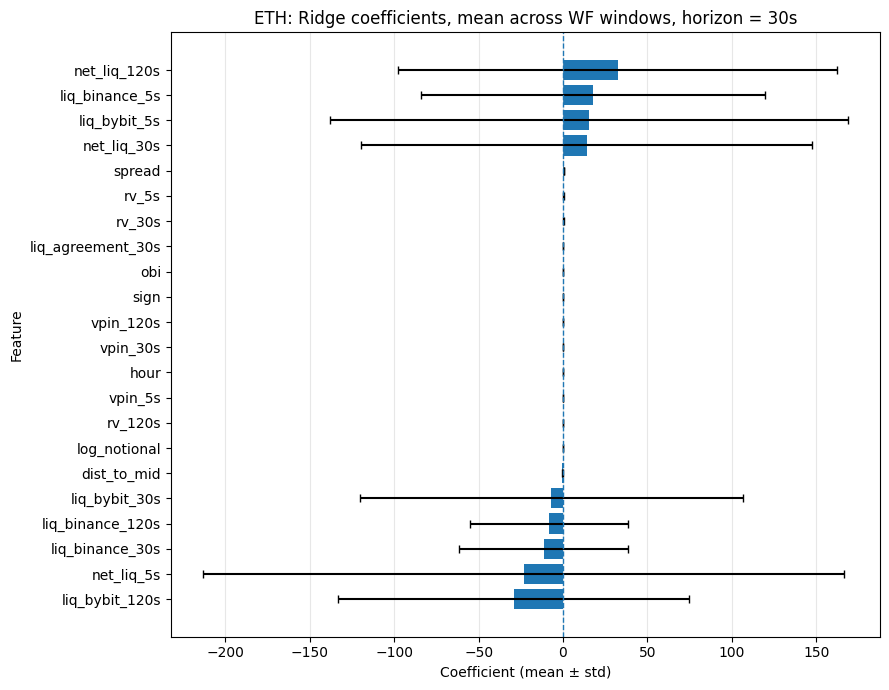

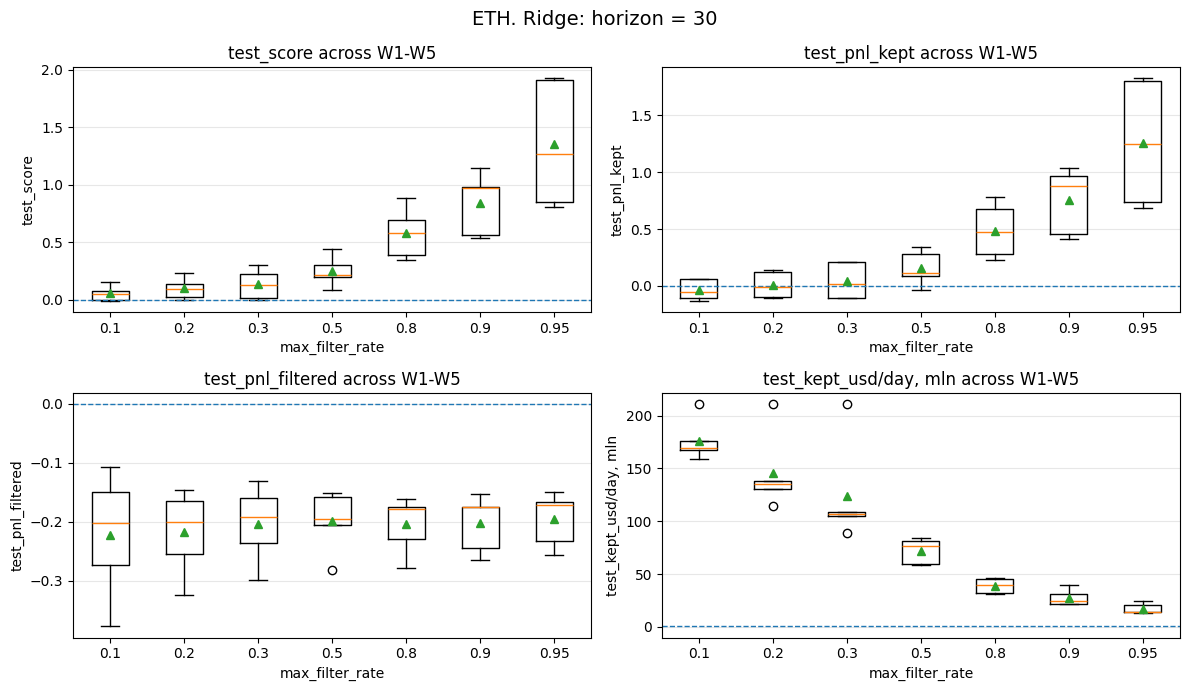

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

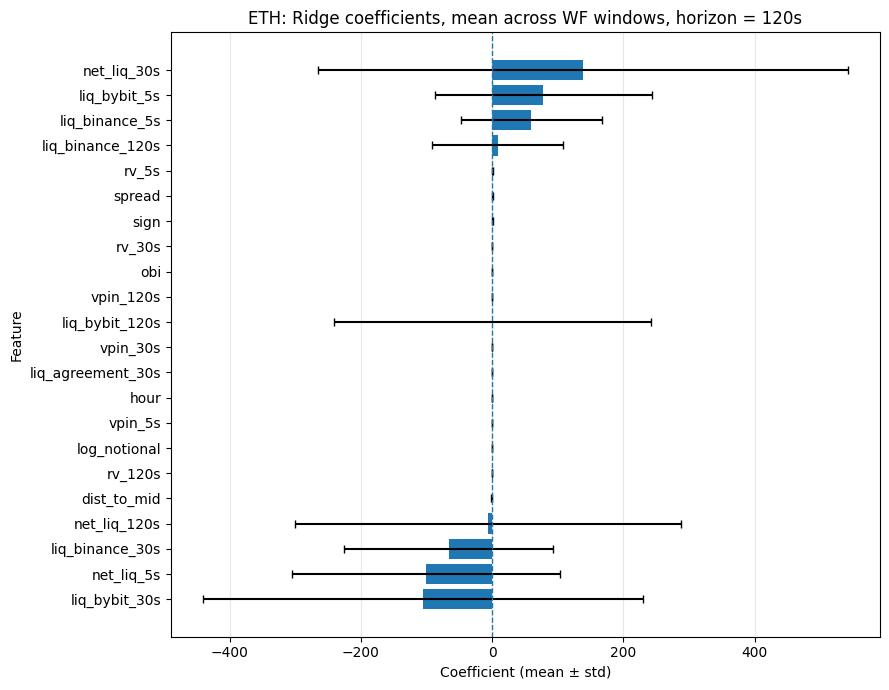

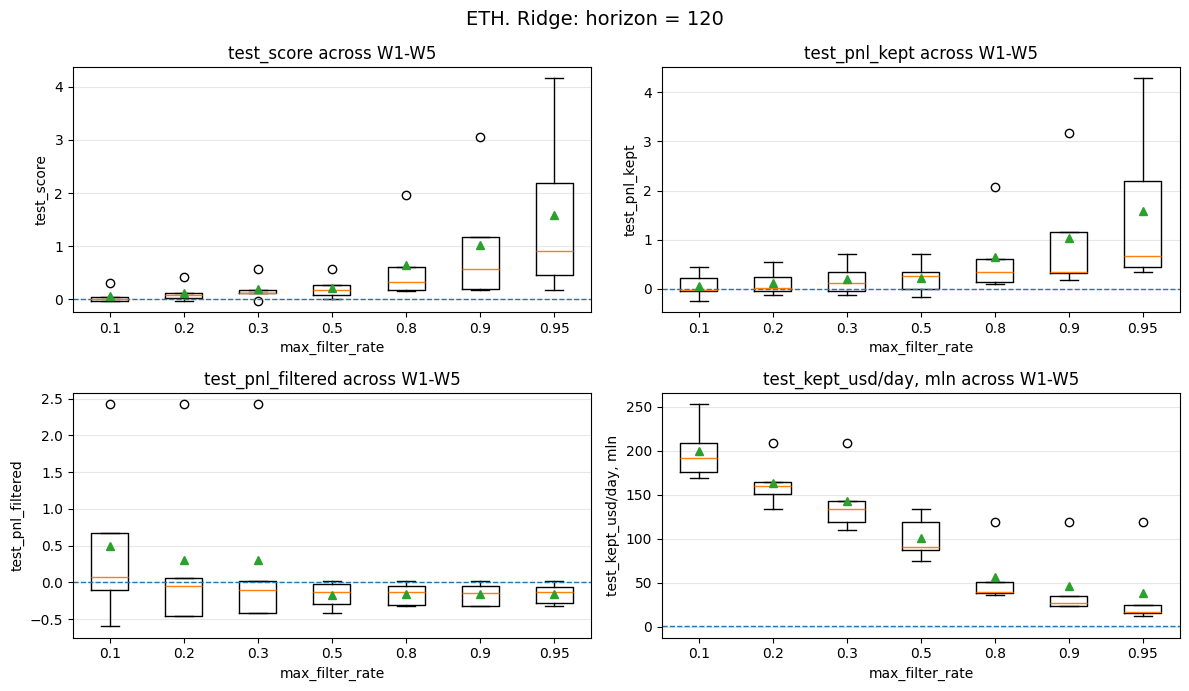

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

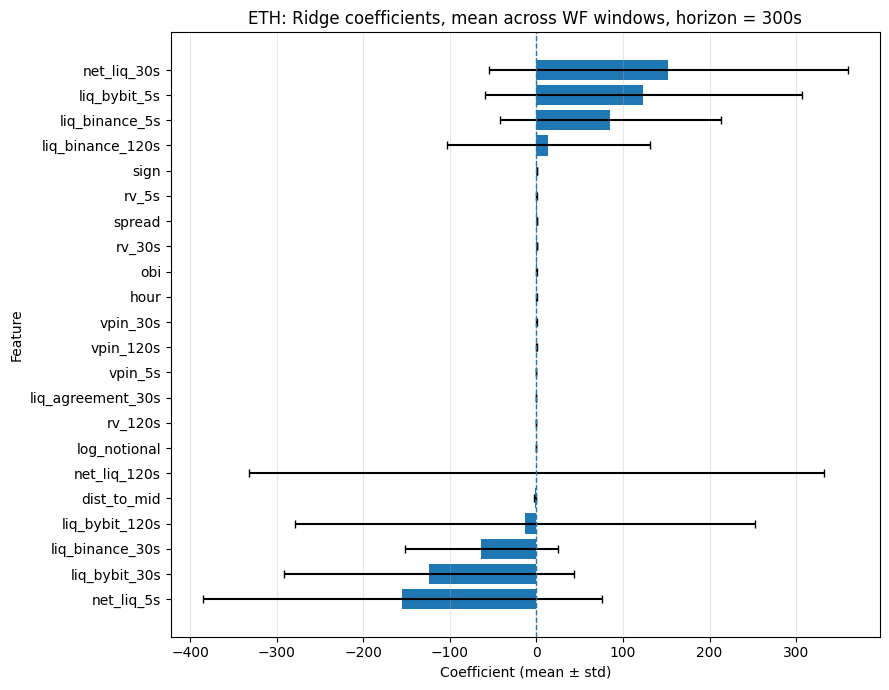

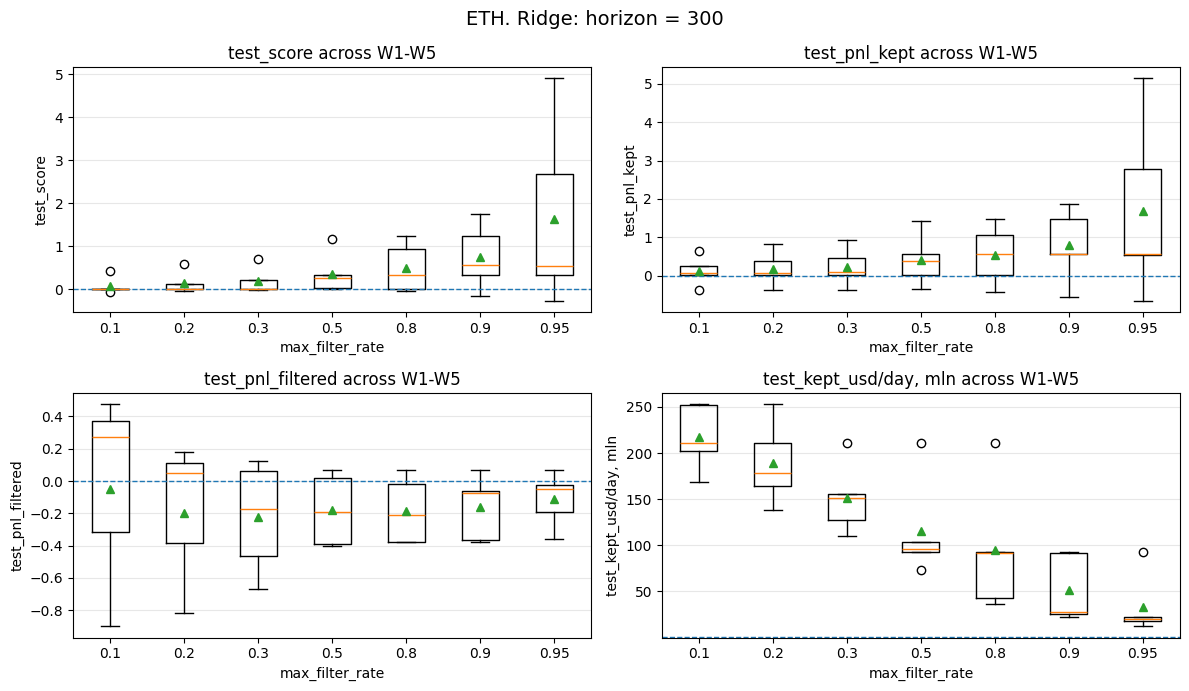

In [ ]:
config_ridge = um.CUSTOM_MODELS["Ridge"]

for tau in HORIZONS:

    # train models / walk-forward test.
    ridge_all, ridge_models = ut4.run_walk_forward(
        df               = data,
        tau              = tau,
        train_fn         = config_ridge["train_fn"],
        predict_fn       = config_ridge["predict_fn"],
        prediction_type  = "pnl",
        max_filter_rates = MAX_FILTER_RATES,
        calib_frac       = 0.20
    )

    # plot linear coefficients.
    ur.plot_linear_coefficients(
        models   = ridge_models,
        top_n    = 30,
        interval = "std",
        figsize  = (9, 7),
        title    = f"{INSTRUMENT}: Ridge coefficients, mean across WF windows, horizon = {tau}s"
    )

    # plot pnl results.
    ur.plot_test_metrics_boxplots(
        result_table = ridge_all,
        model_name   = "Ridge",
        rate_col     = "max_filter_rate",
        instrument   = INSTRUMENT,
        tau          = tau
    )

## <b>Nonlinear Model. LightGBM regression. Weigted MSE loss.</b>

В базовой версии LightGBM обучается с weighted MSE loss:

$
Loss =
\sum_i w_i (y_i - \hat y_i)^2.
$

Здесь $w_i$ - вес сделки, то есть clipped notional.

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

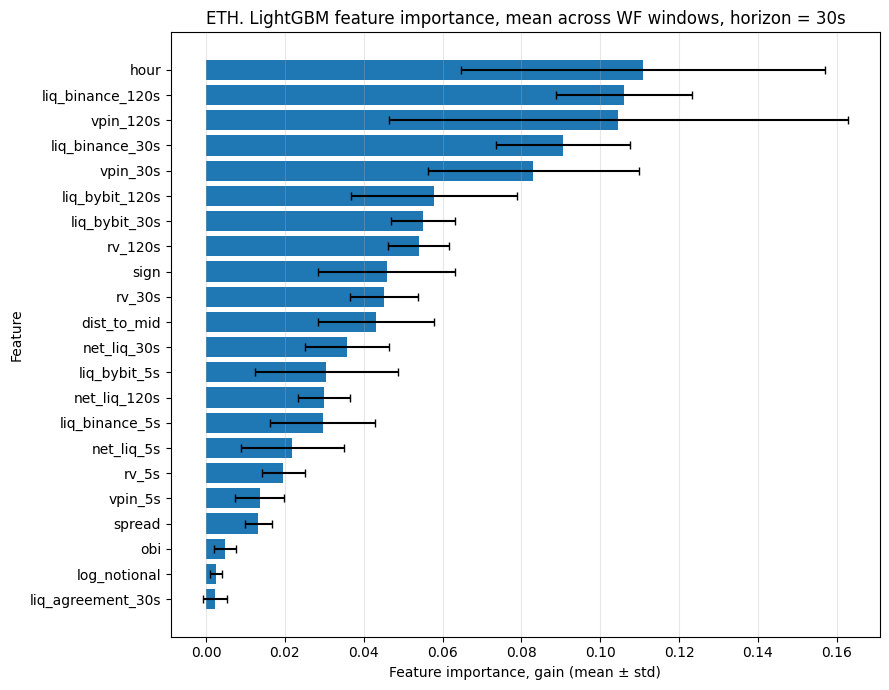

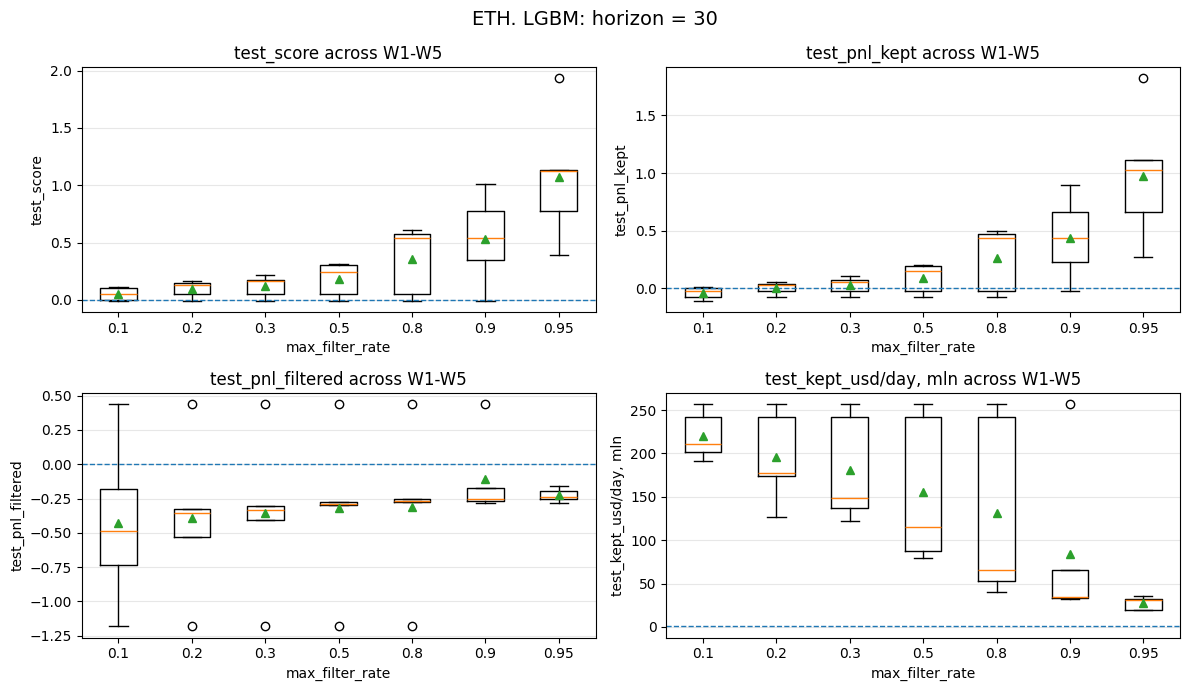

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

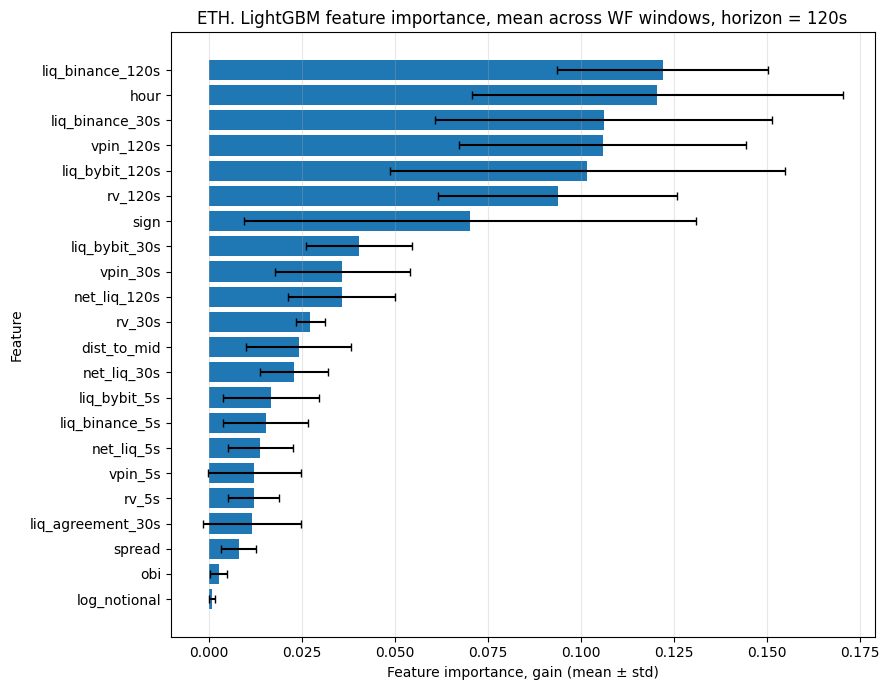

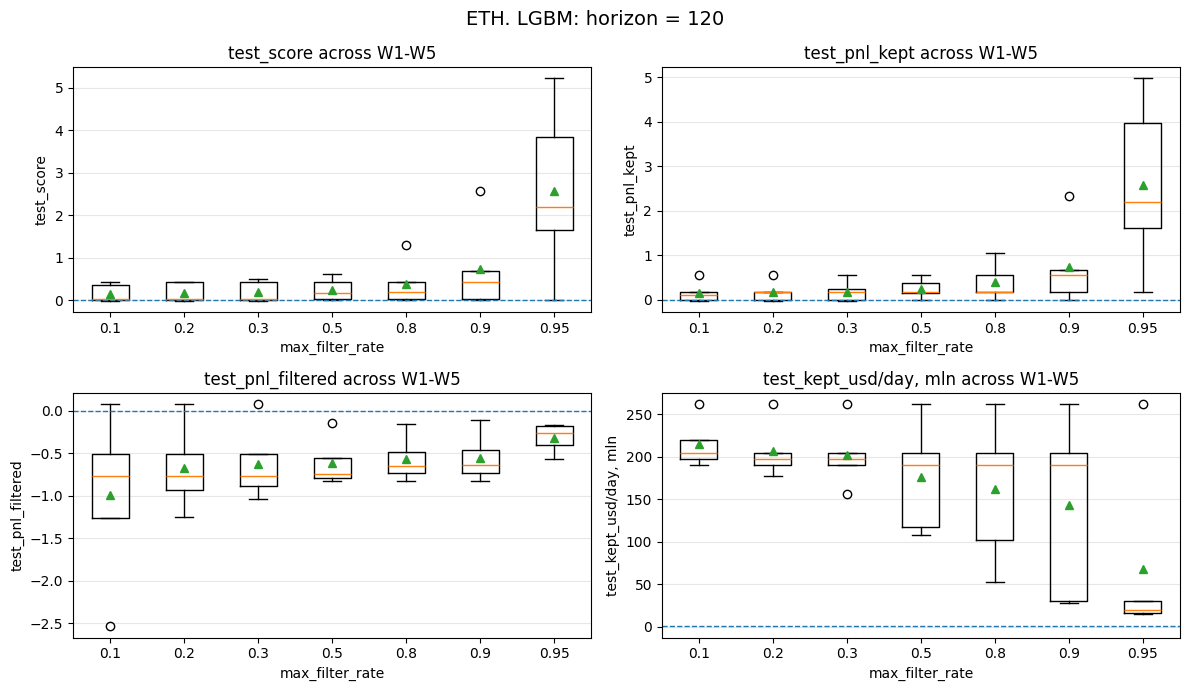

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

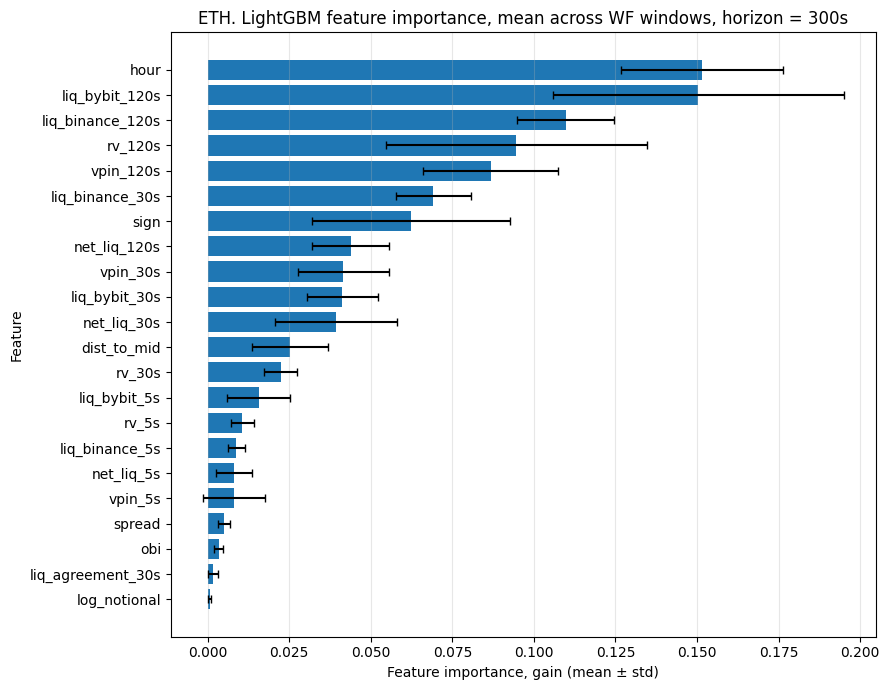

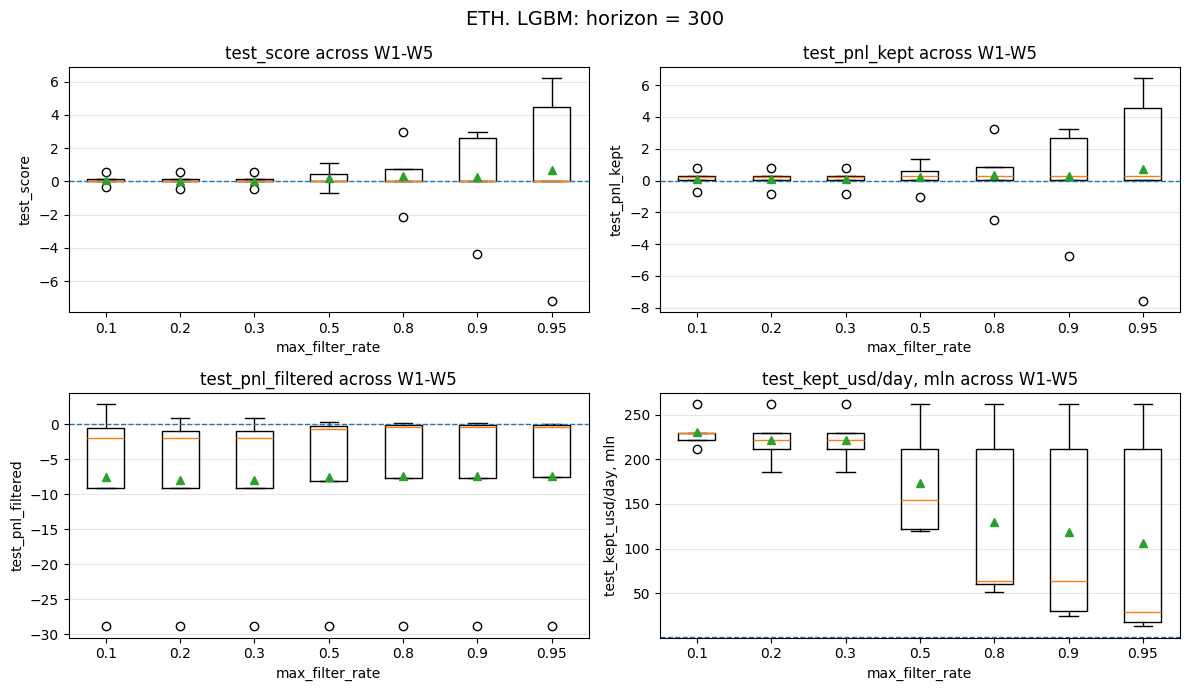

In [4]:
for tau in HORIZONS:

    # train models / walk-forward test.
    config_lgbm = um.CUSTOM_MODELS["LightGBM"]
    lgbm_all, lgbm_models = ut4.run_walk_forward(
        df               = data,
        tau              = tau,
        train_fn         = config_lgbm["train_fn"],
        predict_fn       = config_lgbm["predict_fn"],
        prediction_type  = "pnl",
        max_filter_rates = MAX_FILTER_RATES,
        calib_frac       = 0.20
    )

    # plot feature importance.
    ur.plot_lgbm_feature_importance(
        models              = lgbm_models,
        top_n               = 30,
        importance_type     = "gain",
        interval            = "std",
        normalize_per_model = True,
        figsize             = (9, 7),
        title               = f"{INSTRUMENT}. LightGBM feature importance, mean across WF windows, horizon = {tau}s"
    )

    # plot pnl results.
    ur.plot_test_metrics_boxplots(
        result_table    = lgbm_all,
        model_name      = "LGBM",
        rate_col        = "max_filter_rate",
        instrument      = INSTRUMENT,
        tau             = tau    
    )

## <b>Nonlinear Model. LightGBM regression. Huber loss.</b>

В данной версии LightGBM обучается с Huber loss, который устойчивее к большим выбросам PnL, чем обычный MSE.

$
Loss =
\sum_i w_i \cdot H_\delta(y_i - \hat y_i).
$

Где Huber loss задаётся как:

$
H_\delta(r_i) =
\begin{cases}
\frac{1}{2}r_i^2, & |r_i| \le \delta, \\
\delta(|r_i| - \frac{1}{2}\delta), & |r_i| > \delta.
\end{cases}
$

Здесь:

$
r_i = y_i - \hat y_i
$ - ошибка предсказания PnL, а $w_i$ - вес сделки, то есть clipped notional.

Huber loss ведёт себя как MSE для небольших ошибок и как MAE для больших ошибок, поэтому модель меньше переобучается на экстремальные PnL-выбросы.

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

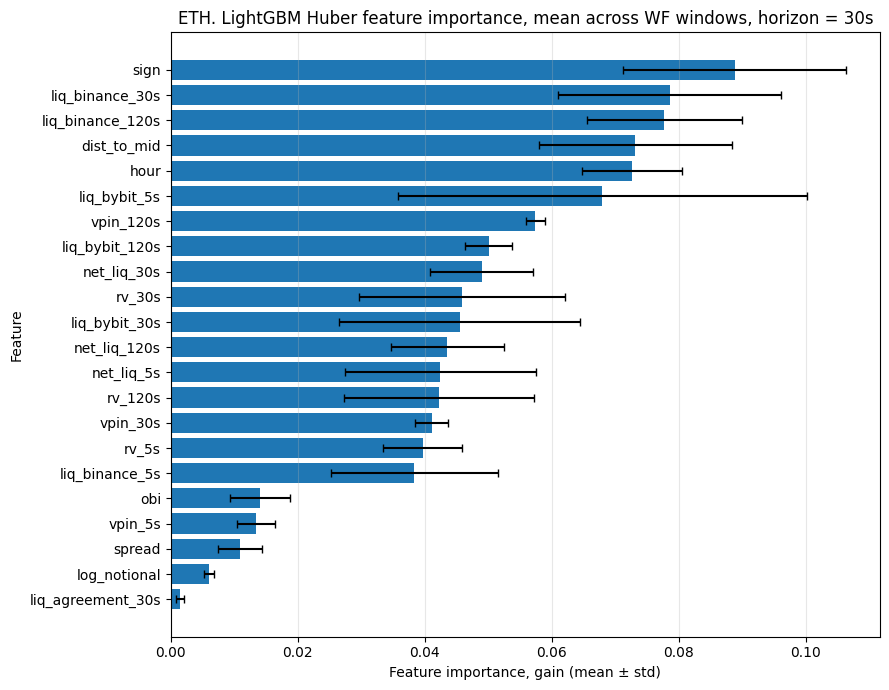

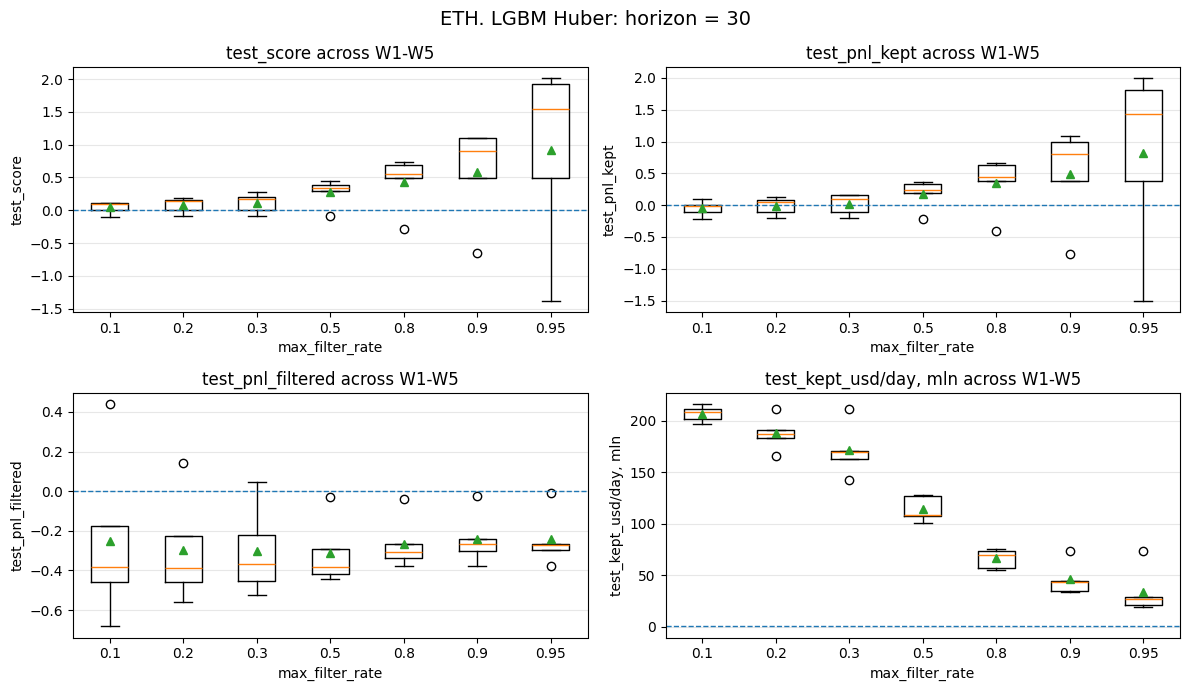

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

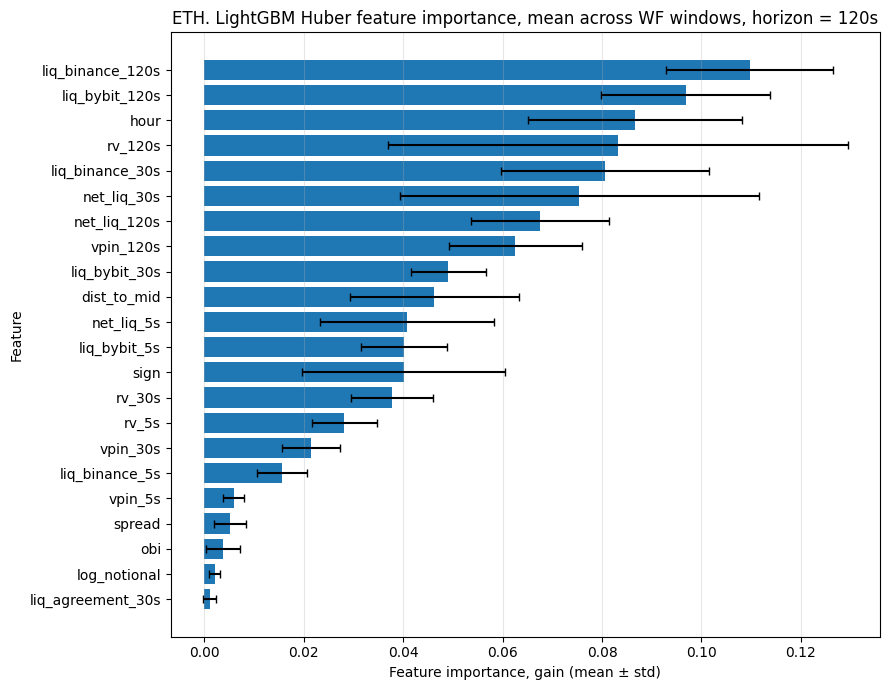

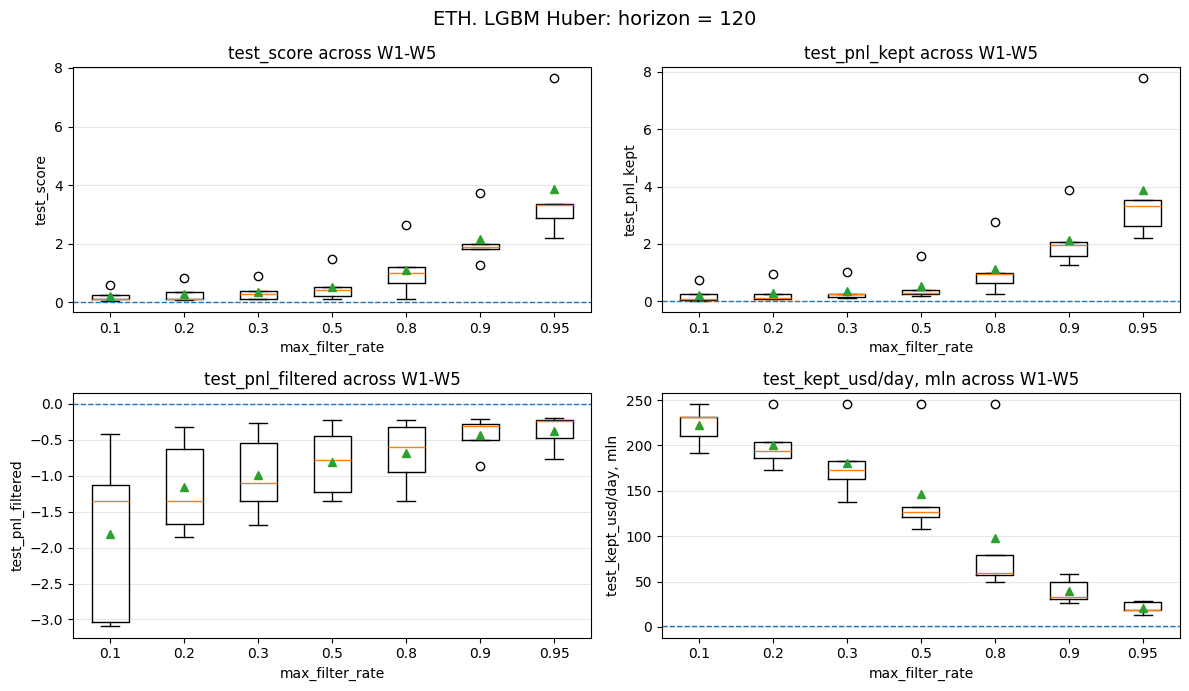

Walk-forward windows:   0%|          | 0/5 [00:00<?, ?it/s]

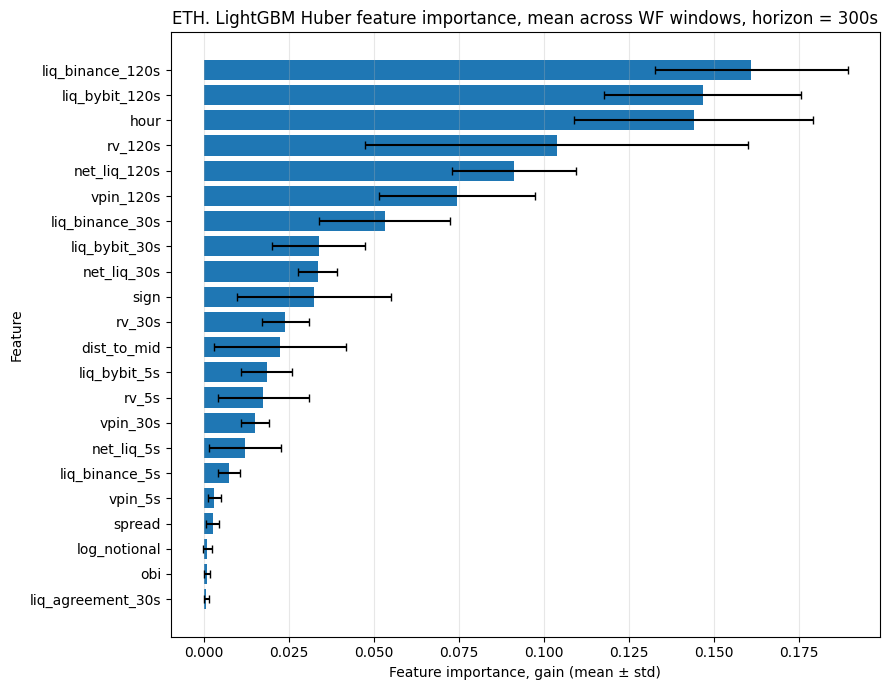

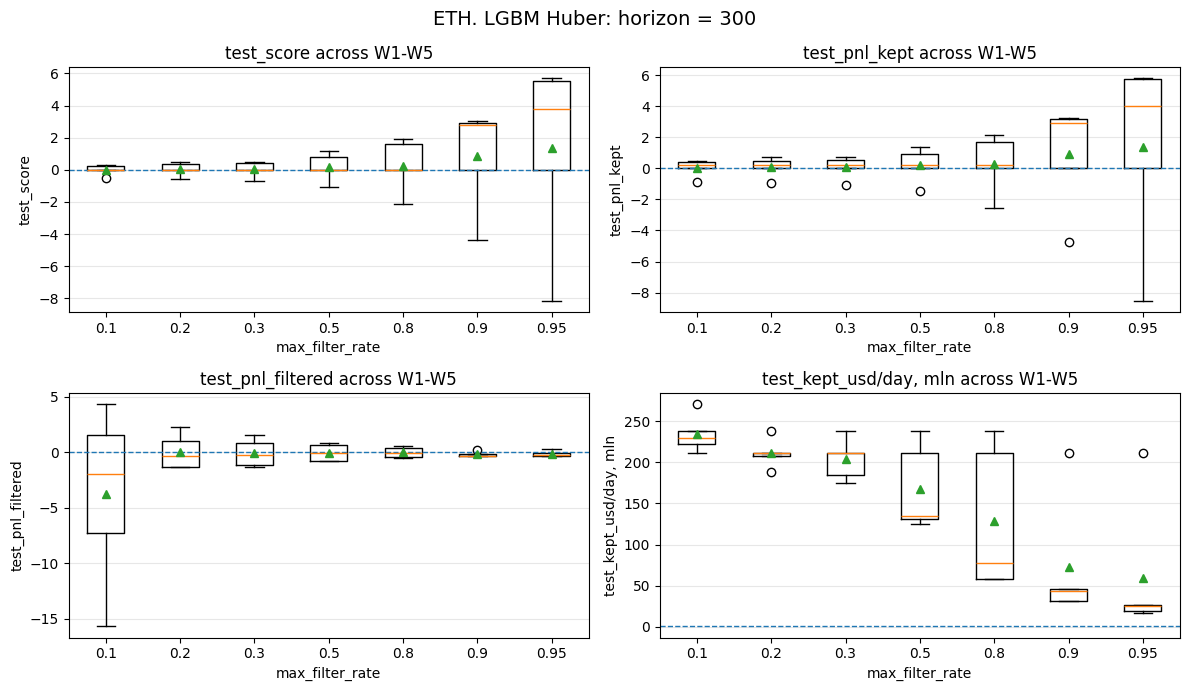

In [4]:
for tau in HORIZONS:

    # train models / walk-forward test.
    config_lgbm = um.CUSTOM_MODELS["LGBM_Huber"]
    lgbm_huber_all, lgbm_huber_models = ut4.run_walk_forward(
        df               = data,
        tau              = tau,
        train_fn         = config_lgbm["train_fn"],
        predict_fn       = config_lgbm["predict_fn"],
        prediction_type  = "pnl",
        max_filter_rates = MAX_FILTER_RATES,
        calib_frac       = 0.20
    )

    # plot feature importance.
    ur.plot_lgbm_feature_importance(
        models              = lgbm_huber_models,
        top_n               = 30,
        importance_type     = "gain",
        interval            = "std",
        normalize_per_model = True,
        figsize             = (9, 7),
        title               = f"{INSTRUMENT}. LightGBM Huber feature importance, mean across WF windows, horizon = {tau}s"
    )

    # plot pnl results.
    ur.plot_test_metrics_boxplots(
        result_table    = lgbm_huber_all,
        model_name      = "LGBM Huber",
        rate_col        = "max_filter_rate",
        instrument      = INSTRUMENT, 
        tau             = tau    
    )

## <b>Statistical comparison of models.</b>

Визуальное сравнение boxplot'ов показывает, что LGBM Huber даёт наибольший Score, но этого недостаточно: разница между моделями может быть вызвана случайным стечением рыночных режимов в тестовых окнах W1–W5.

Для строгого ответа на вопрос "значимо ли одна модель лучше другой" применяем четыре статистических теста на **дневных** Score'ах, агрегированных из OOS-предсказаний всех пяти окон.

Дневная агрегация необходима, поскольку per-trade Score'ы автокоррелированы из-за перекрытия маркаут-окон ($\tau \le 300\text{s}$). На дневном уровне ($86\,400\text{s} \gg 300\text{s}$) автокорреляция устранена, что было показано в Task 3 (ACF(1) внутри полосы Бартлетта).

**Тест 1. Pairwise DM-HAC.** Нулевая гипотеза: $H_0\!: \mathbb{E}[\text{Score}_A(t) - \text{Score}_B(t)] \le 0$. Отвергаем, если модель $A$ значимо лучше $B$.

**Тест 2. Hansen SPA.** Нулевая гипотеза: ни одна ML-модель не лучше Rule-based бейзлайна. Если $p < 0.05$, значит хотя бы одна модель генуинно превосходит бейзлайн с учётом множественности сравнений (data snooping).

**Тест 3. Model Confidence Set (MCS).** Итеративная элиминация худшей модели до тех пор, пока оставшиеся статистически неразличимы при $\alpha = 0.05$. Результат - множество моделей, содержащее лучшую с вероятностью $\ge 95\%$.

**Тест 4. Romano-Wolf stepdown.** Проверка для каждой модели: «лучше ли она Rule-based?» с контролем FWER (family-wise error rate) на уровне $\alpha = 0.05$. В отличие от Bonferroni, учитывает корреляцию между тест-статистиками и обладает большей мощностью.

In [ ]:
STAT_TAU = 30
STAT_FILTER_RATE = 0.80

# Collect daily scores for each model.

MODEL_SPECS = {
    "RuleBased": {
        **um.CUSTOM_MODELS["RuleBased_DistToMid"],
        "prediction_type": "toxicity",
    },
    "Ridge": {
        **um.CUSTOM_MODELS["Ridge"],
        "prediction_type": "pnl",
    },
    "LightGBM": {
        **um.CUSTOM_MODELS["LightGBM"],
        "prediction_type": "pnl",
    },
    "LGBM_Huber": {
        **um.CUSTOM_MODELS["LGBM_Huber"],
        "prediction_type": "pnl",
    },
}

daily_scores = {}

for name, spec in MODEL_SPECS.items():
    print(f"Collecting OOS for {name}...")

    y_oos, w_oos, ts_oos, f_oos = ut4.collect_oos_arrays(
        df               = data,
        tau              = STAT_TAU,
        train_fn         = spec["train_fn"],
        predict_fn       = spec["predict_fn"],
        prediction_type  = spec["prediction_type"],
        max_filter_rate  = STAT_FILTER_RATE,
        calib_frac       = 0.20
    )

    ds = ut4.compute_daily_scores_from_arrays(y_oos, w_oos, ts_oos, f_oos)
    daily_scores[name] = ds
    print(f"  {name}: {len(ds)} days, mean={ds.mean():+.4f}, std={ds.std():.4f}")

# align lengths (all should be same if OOS periods identical).
min_len = min(len(v) for v in daily_scores.values())
daily_scores = {k: v[:min_len] for k, v in daily_scores.items()}

print(f"\nAligned to {min_len} days.")

  RuleBased: 114 days, mean=+0.3457, std=1.1278
  Ridge: 114 days, mean=+0.6640, std=1.1254
  LightGBM: 114 days, mean=+0.3624, std=1.0688
  LGBM_Huber: 114 days, mean=+0.6190, std=1.8442

Aligned to 114 days.


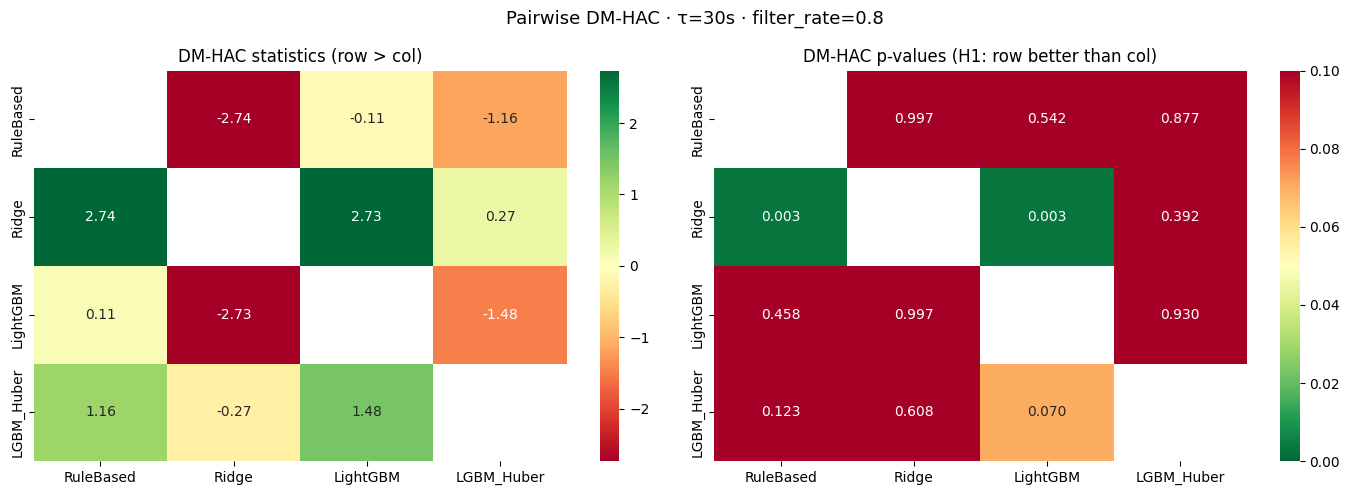

In [11]:
# 1. Pairwise DM-HAC

names, dm_stats, p_values = pairwise_dm_matrix(daily_scores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mask_diag = np.eye(len(names), dtype=bool)

sns.heatmap(
    np.where(mask_diag, np.nan, dm_stats),
    xticklabels=names, yticklabels=names,
    annot=True, fmt=".2f", cmap="RdYlGn", center=0,
    ax=axes[0],
)
axes[0].set_title("DM-HAC statistics (row > col)")

sns.heatmap(
    np.where(mask_diag, np.nan, p_values),
    xticklabels=names, yticklabels=names,
    annot=True, fmt=".3f", cmap="RdYlGn_r", vmin=0, vmax=0.1,
    ax=axes[1],
)
axes[1].set_title("DM-HAC p-values (H1: row better than col)")

plt.suptitle(f"Pairwise DM-HAC · τ={STAT_TAU}s · filter_rate={STAT_FILTER_RATE}", fontsize=13)
plt.tight_layout()
plt.show()

In [12]:
# 2. Hansen SPA: is any model better than Rule-based?.
spa = hansen_spa_test(
    daily_scores    = daily_scores,
    benchmark_name  = "RuleBased",
    n_boot          = 5000,
    alpha           = 0.05
)

print("Hansen SPA test")
print(f"  H0: no model is better than RuleBased")
print(f"  Test statistic: {spa.test_stat}")
print(f"  p-value: {spa.p_value}")
print(f"  Reject H0: {spa.reject_h0}")
print(f"  Best filter: {spa.best_filter} (mean diff = {spa.best_mean_diff:+.4f} bps/day)")

Hansen SPA test
  H0: no model is better than RuleBased
  Test statistic: 2.7358
  p-value: 0.0008
  Reject H0: True
  Best filter: Ridge (mean diff = +0.3182 bps/day)


In [13]:
# 3. Model Confidence Set.
mcs = model_confidence_set(
    daily_scores = daily_scores,
    n_boot       = 5000,
    alpha        = 0.05
)

print("Model Confidence Set (0.05)")
print(f"  In MCS (statistically indistinguishable from best):")
for name in mcs.confidence_set:
    print(f"    {name}")
print(f"  Eliminated:")
for name in mcs.eliminated:
    print(f"    {name} (p={mcs.elimination_pvals[name]:.4f})")

Model Confidence Set (0.05)
  In MCS (statistically indistinguishable from best):
    Ridge
    LGBM_Huber
  Eliminated:
    RuleBased (p=0.0008)
    LightGBM (p=0.0050)


In [14]:
# 4. Romano-Wolf stepdown (FWER control).
rw = romano_wolf_stepdown(
    daily_scores    = daily_scores,
    benchmark_name  = "RuleBased",
    n_boot          = 5000,
    alpha           = 0.05
)

print("Romano-Wolf stepdown (vs RuleBased, FWER=0.05)")
print(f"  Rejected (significantly better than RuleBased):")
for name in rw.rejected:
    print(f"    {name} (adj. p={rw.adjusted_pvalues[name]:.4f})")
print(f"  Not rejected:")
for name in rw.not_rejected:
    print(f"    {name} (adj. p={rw.adjusted_pvalues[name]:.4f})")

Romano-Wolf stepdown (vs RuleBased, FWER=0.05)
  Rejected (significantly better than RuleBased):
    Ridge (adj. p=0.0008)
  Not rejected:
    LightGBM (adj. p=0.1652)
    LGBM_Huber (adj. p=0.1652)


In [15]:
# Summary table.
summary_rows = []
for name, ds in daily_scores.items():
    in_mcs = name in mcs.confidence_set
    rw_rejected = name in rw.rejected
    summary_rows.append({
        "Model": name,
        "Mean daily Score": round(ds.mean(), 4),
        "Std": round(ds.std(), 4),
        "In MCS": in_mcs,
        "Beats RuleBased (RW)": rw_rejected if name != "RuleBased" else "—",
        "RW adj. p-value": rw.adjusted_pvalues.get(name, "—"),
    })

summary_df = pd.DataFrame(summary_rows)
print(f"\nStatistical comparison summary · τ={STAT_TAU}s · filter_rate={STAT_FILTER_RATE}")
display(summary_df)


Statistical comparison summary · τ=30s · filter_rate=0.8


,Model,Mean daily Score,Std,In MCS,Beats RuleBased (RW),RW adj. p-value
0,RuleBased,0.3457,1.1278,False,—,—
1,Ridge,0.6640,1.1254,True,True,0.0008
2,LightGBM,0.3624,1.0688,False,False,0.1652
3,LGBM_Huber,0.6190,1.8442,True,False,0.1652


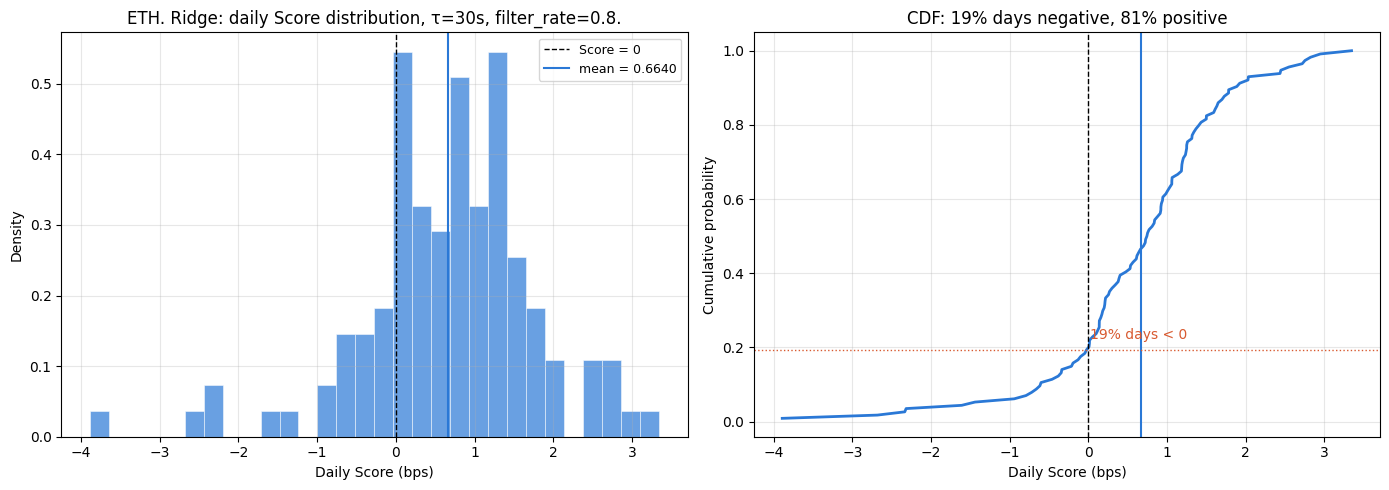


Ridge daily Score stats:
  Mean:   +0.6640 bps
  Std:    1.1254 bps
  Median: +0.7486 bps
  Min:    -3.8900 bps
  Max:    +3.3449 bps
  Days>0: 92/114 (81%)
  Days<0: 22/114 (19%)


In [ ]:
ds = daily_scores["Ridge"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram + fitted normal.
ax = axes[0]
ax.hist(ds, bins=30, density=True, alpha=0.7, color="#2a78d6", edgecolor="white", linewidth=0.5)

mu, sigma = ds.mean(), ds.std()

ax.axvline(0, linestyle="--", color="black", linewidth=1, label="Score = 0")
ax.axvline(mu, linestyle="-", color="#2a78d6", linewidth=1.5, label=f"mean = {mu:.4f}")
ax.set_xlabel("Daily Score (bps)")
ax.set_ylabel("Density")
ax.set_title(f"{INSTRUMENT}. Ridge: daily Score distribution, τ={STAT_TAU}s, filter_rate={STAT_FILTER_RATE}.")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# 2. Cumulative distribution.
ax = axes[1]
sorted_ds = np.sort(ds)
cdf = np.arange(1, len(sorted_ds) + 1) / len(sorted_ds)
ax.plot(sorted_ds, cdf, color="#2a78d6", linewidth=2)
ax.axvline(0, linestyle="--", color="black", linewidth=1)
ax.axvline(mu, linestyle="-", color="#2a78d6", linewidth=1.5)

# shade negative region.
neg_frac = (ds < 0).mean()
ax.axhline(neg_frac, linestyle=":", color="#d85a30", linewidth=1)
ax.text(0.02, neg_frac + 0.03, f"{neg_frac*100:.0f}% days < 0", color="#d85a30", fontsize=10)

ax.set_xlabel("Daily Score (bps)")
ax.set_ylabel("Cumulative probability")
ax.set_title(f"CDF: {neg_frac*100:.0f}% days negative, {(1-neg_frac)*100:.0f}% positive")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nRidge daily Score stats:")
print(f"  Mean:   {mu:+.4f} bps")
print(f"  Std:    {sigma:.4f} bps")
print(f"  Median: {np.median(ds):+.4f} bps")
print(f"  Min:    {ds.min():+.4f} bps")
print(f"  Max:    {ds.max():+.4f} bps")
print(f"  Days>0: {(ds>0).sum()}/{len(ds)} ({(ds>0).mean()*100:.0f}%)")
print(f"  Days<0: {(ds<0).sum()}/{len(ds)} ({(ds<0).mean()*100:.0f}%)")

## <b>Plot best results Distribution.</b>

In [5]:
ETH_BEST_SETTINGS = [
    {"tau": 120, "filter_rate": 0.90, "label": "ETH_120s_fr090_stable"},
    {"tau": 120, "filter_rate": 0.95, "label": "ETH_120s_fr095_aggressive"},
]

BEST_MODEL_NAME = "LGBM_Huber"

best_model_spec = {
    **um.CUSTOM_MODELS[BEST_MODEL_NAME],
    "prediction_type": "pnl"
}

eth_best_daily_scores = {}
eth_best_daily_pnl_kept = {}
eth_best_oos_arrays = {}

for setting in ETH_BEST_SETTINGS:

    STAT_TAU = setting["tau"]
    STAT_FILTER_RATE = setting["filter_rate"]
    LABEL = setting["label"]

    print("=" * 90)
    print(f"Setting: {LABEL}")
    print(f"Model: {BEST_MODEL_NAME}")
    print(f"STAT_TAU = {STAT_TAU}, STAT_FILTER_RATE = {STAT_FILTER_RATE}")
    print("=" * 90)

    y_oos, w_oos, ts_oos, f_oos = ut4.collect_oos_arrays(
        df               = data,
        tau              = STAT_TAU,
        train_fn         = best_model_spec["train_fn"],
        predict_fn       = best_model_spec["predict_fn"],
        prediction_type  = best_model_spec["prediction_type"],
        max_filter_rate  = STAT_FILTER_RATE,
        calib_frac       = 0.20
    )

    ds_score = ut4.compute_daily_scores_from_arrays(
        y  = y_oos,
        w  = w_oos,
        ts = ts_oos,
        f  = f_oos
    )

    ds_kept = ut4.compute_daily_pnl_kept_from_arrays(
        y  = y_oos,
        w  = w_oos,
        ts = ts_oos,
        f  = f_oos
    )

    eth_best_daily_scores[LABEL] = ds_score
    eth_best_daily_pnl_kept[LABEL] = ds_kept
    eth_best_oos_arrays[LABEL] = {
        "y": y_oos,
        "w": w_oos,
        "ts": ts_oos,
        "f": f_oos,
    }

    print(
        f"\n{LABEL}: "
        f"daily_score mean={ds_score.mean():+.4f}, std={ds_score.std():.4f}; "
        f"daily_pnl_kept mean={ds_kept.mean():+.4f}, std={ds_kept.std():.4f}"
    )
    print(
        f"Days Score > 0: {(ds_score > 0).sum()}/{len(ds_score)} "
        f"({(ds_score > 0).mean() * 100:.0f}%)"
    )
    print(
        f"Days PnL kept > 0: {(ds_kept > 0).sum()}/{len(ds_kept)} "
        f"({(ds_kept > 0).mean() * 100:.0f}%)"
    )

Setting: ETH_120s_fr090_stable
Model: LGBM_Huber
STAT_TAU = 120, STAT_FILTER_RATE = 0.9

ETH_120s_fr090_stable: daily_score mean=+2.1031, std=4.4680; daily_pnl_kept mean=+2.1051, std=4.8111
Days Score > 0: 82/114 (72%)
Days PnL kept > 0: 83/114 (73%)
Setting: ETH_120s_fr095_aggressive
Model: LGBM_Huber
STAT_TAU = 120, STAT_FILTER_RATE = 0.95

ETH_120s_fr095_aggressive: daily_score mean=+3.7062, std=7.2512; daily_pnl_kept mean=+3.7082, std=7.5782
Days Score > 0: 89/114 (78%)
Days PnL kept > 0: 84/114 (74%)


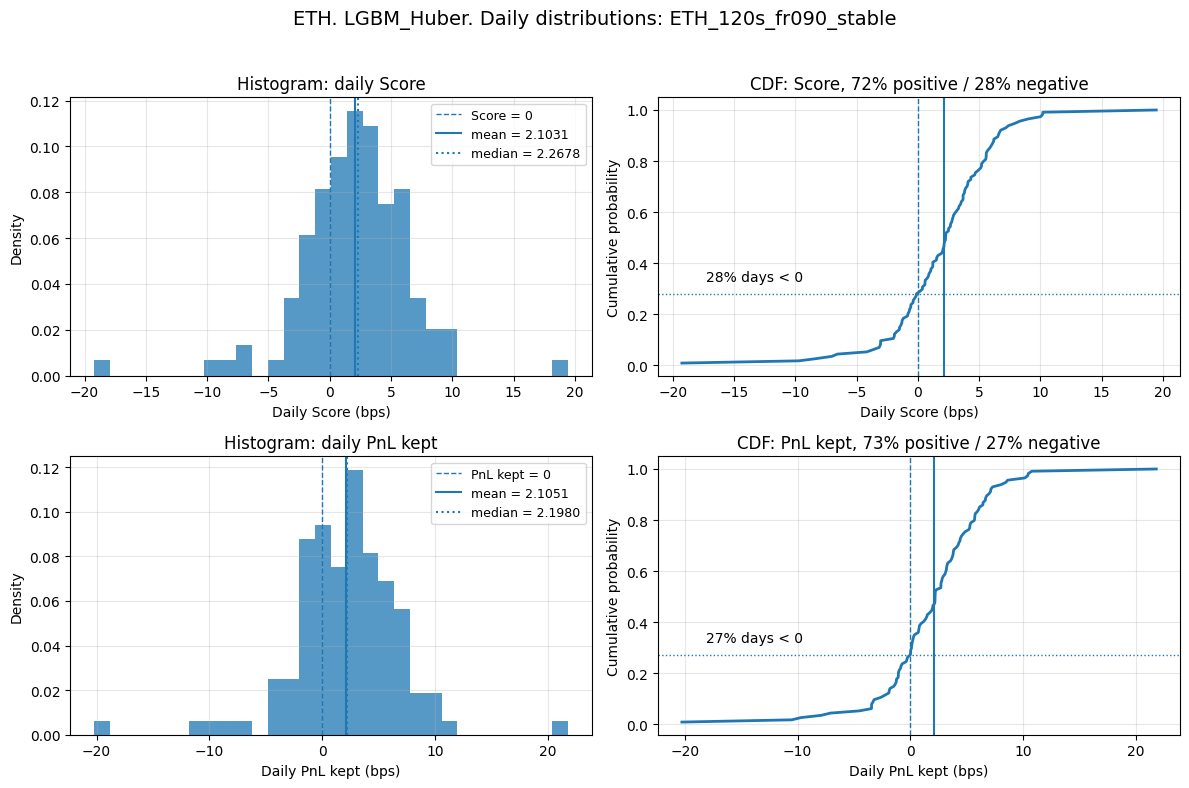


ETH_120s_fr090_stable
Daily Score:
  mean   = +2.1031
  std    = 4.4680
  median = +2.2678
  min    = -19.2461
  max    = +19.4485
  >0 days: 82/114 (72%)
Daily PnL kept:
  mean   = +2.1051
  std    = 4.8111
  median = +2.1980
  min    = -20.2498
  max    = +21.7994
  >0 days: 83/114 (73%)


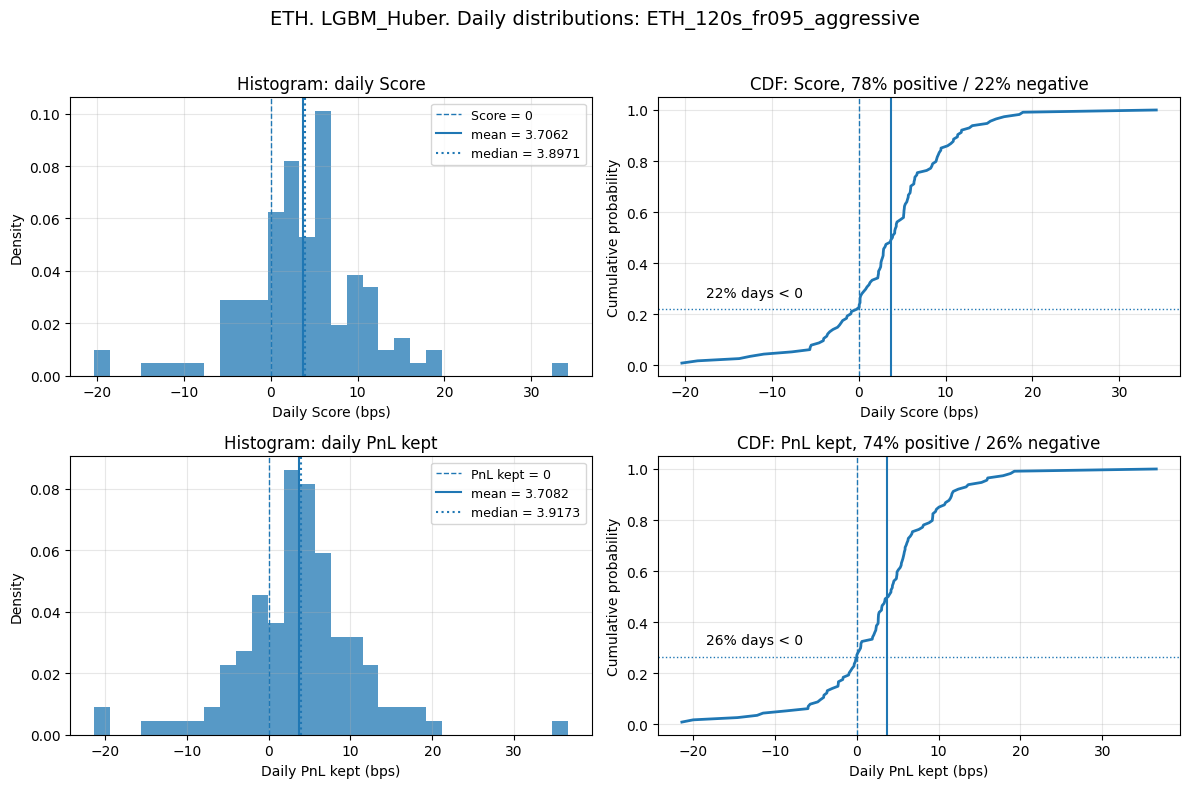


ETH_120s_fr095_aggressive
Daily Score:
  mean   = +3.7062
  std    = 7.2512
  median = +3.8971
  min    = -20.3726
  max    = +34.2558
  >0 days: 89/114 (78%)
Daily PnL kept:
  mean   = +3.7082
  std    = 7.5782
  median = +3.9173
  min    = -21.3763
  max    = +36.6067
  >0 days: 84/114 (74%)


In [7]:
SETTINGS_TO_PLOT = [
    "ETH_120s_fr090_stable",
    "ETH_120s_fr095_aggressive",
]

for setting_name in SETTINGS_TO_PLOT:

    ds_score = np.asarray(eth_best_daily_scores[setting_name], dtype=float)
    ds_kept  = np.asarray(eth_best_daily_pnl_kept[setting_name], dtype=float)

    ds_score = ds_score[np.isfinite(ds_score)]
    ds_kept  = ds_kept[np.isfinite(ds_kept)]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # 1. Histogram: daily score.
    ax = axes[0, 0]

    mu_score = ds_score.mean()
    sigma_score = ds_score.std()
    median_score = np.median(ds_score)

    ax.hist(ds_score, bins=30, density=True, alpha=0.75)
    ax.axvline(0, linestyle="--", linewidth=1, label="Score = 0")
    ax.axvline(mu_score, linestyle="-", linewidth=1.5, label=f"mean = {mu_score:.4f}")
    ax.axvline(median_score, linestyle=":", linewidth=1.5, label=f"median = {median_score:.4f}")

    ax.set_xlabel("Daily Score (bps)")
    ax.set_ylabel("Density")
    ax.set_title("Histogram: daily Score")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)


    # 2. CDF: daily score.
    ax = axes[0, 1]

    sorted_score = np.sort(ds_score)
    cdf_score = np.arange(1, len(sorted_score) + 1) / len(sorted_score)
    neg_frac_score = (ds_score < 0).mean()

    ax.plot(sorted_score, cdf_score, linewidth=2)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.axvline(mu_score, linestyle="-", linewidth=1.5)
    ax.axhline(neg_frac_score, linestyle=":", linewidth=1)

    x_text_score = sorted_score.min() + 0.05 * (sorted_score.max() - sorted_score.min())
    y_text_score = min(0.97, neg_frac_score + 0.05)
    ax.text(
        x_text_score,
        y_text_score,
        f"{neg_frac_score*100:.0f}% days < 0",
        fontsize=10
    )

    ax.set_xlabel("Daily Score (bps)")
    ax.set_ylabel("Cumulative probability")
    ax.set_title(
        f"CDF: Score, {(1 - neg_frac_score)*100:.0f}% positive / {neg_frac_score*100:.0f}% negative"
    )
    ax.grid(alpha=0.3)


    # 3. Histogram: daily pnl kept.
    ax = axes[1, 0]

    mu_kept = ds_kept.mean()
    sigma_kept = ds_kept.std()
    median_kept = np.median(ds_kept)

    ax.hist(ds_kept, bins=30, density=True, alpha=0.75)
    ax.axvline(0, linestyle="--", linewidth=1, label="PnL kept = 0")
    ax.axvline(mu_kept, linestyle="-", linewidth=1.5, label=f"mean = {mu_kept:.4f}")
    ax.axvline(median_kept, linestyle=":", linewidth=1.5, label=f"median = {median_kept:.4f}")

    ax.set_xlabel("Daily PnL kept (bps)")
    ax.set_ylabel("Density")
    ax.set_title("Histogram: daily PnL kept")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)


    # 4. CDF: daily pnl kept.
    ax = axes[1, 1]

    sorted_kept = np.sort(ds_kept)
    cdf_kept = np.arange(1, len(sorted_kept) + 1) / len(sorted_kept)
    neg_frac_kept = (ds_kept < 0).mean()

    ax.plot(sorted_kept, cdf_kept, linewidth=2)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.axvline(mu_kept, linestyle="-", linewidth=1.5)
    ax.axhline(neg_frac_kept, linestyle=":", linewidth=1)

    x_text_kept = sorted_kept.min() + 0.05 * (sorted_kept.max() - sorted_kept.min())
    y_text_kept = min(0.97, neg_frac_kept + 0.05)
    ax.text(
        x_text_kept,
        y_text_kept,
        f"{neg_frac_kept*100:.0f}% days < 0",
        fontsize=10
    )

    ax.set_xlabel("Daily PnL kept (bps)")
    ax.set_ylabel("Cumulative probability")
    ax.set_title(
        f"CDF: PnL kept, {(1 - neg_frac_kept)*100:.0f}% positive / {neg_frac_kept*100:.0f}% negative"
    )
    ax.grid(alpha=0.3)


    # Summary title.
    fig.suptitle(
        f"ETH. LGBM_Huber. Daily distributions: {setting_name}",
        fontsize=14
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Optional numeric summary.
    print(f"\n{setting_name}")
    print("Daily Score:")
    print(f"  mean   = {mu_score:+.4f}")
    print(f"  std    = {sigma_score:.4f}")
    print(f"  median = {median_score:+.4f}")
    print(f"  min    = {ds_score.min():+.4f}")
    print(f"  max    = {ds_score.max():+.4f}")
    print(f"  >0 days: {(ds_score > 0).sum()}/{len(ds_score)} ({(ds_score > 0).mean()*100:.0f}%)")

    print("Daily PnL kept:")
    print(f"  mean   = {mu_kept:+.4f}")
    print(f"  std    = {sigma_kept:.4f}")
    print(f"  median = {median_kept:+.4f}")
    print(f"  min    = {ds_kept.min():+.4f}")
    print(f"  max    = {ds_kept.max():+.4f}")
    print(f"  >0 days: {(ds_kept > 0).sum()}/{len(ds_kept)} ({(ds_kept > 0).mean()*100:.0f}%)")